# 12 — Ensembling

[Previous](./11_Hyperparameter_Optimization.ipynb) | [Repository guide](../README.md) | [Next](./13_Calibration_and_Thresholds.ipynb)

> This public copy includes the saved Kaggle outputs, so every table, chart, and score can be inspected on GitHub.

**Goal:** test whether several strong models together are more reliable than the best model alone.

We reuse the tuned **CatBoost**, **LightGBM**, and **MLP** settings from Notebook 11. Features, preprocessing, five folds, original class balance, and the `0.50` threshold stay fixed.


## 1. Ensembling vocabulary

- **Ensemble:** combines predictions from multiple models.
- **Base model:** one individual model inside the ensemble.
- **Diversity:** models make different errors. Combining identical predictions adds little.
- **Hard voting:** each model votes for class `0` or `1`; the majority wins.
- **Soft voting:** average predicted probabilities, then apply the threshold.
- **Weight:** how much influence one model receives in an average.
- **Meta-model:** a second model that learns how to combine base-model predictions.
- **Stacking:** use base predictions as inputs to a meta-model.

An ensemble needs both **quality** and **diversity**. A weak but different model can still hurt the result.


In [1]:
from pathlib import Path
from time import perf_counter
from zipfile import BadZipFile, ZipFile
import hashlib
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

TARGET = "is_scored"
ID_COLUMNS = ["id", "kicker_id", "keeper_id", "match_id"]
RANDOM_STATE = 42
PROJECT_ROOT = Path.cwd()

pd.set_option("display.float_format", lambda value: f"{value:.4f}")
plt.style.use("seaborn-v0_8-whitegrid")
warnings.filterwarnings("ignore", message="X does not have valid feature names")


In [2]:
def data_directories(start="."):
    start = Path(start).resolve()
    candidates = [
        start / "data", start.parent / "data", start,
        Path("/kaggle/input/competitions/penalty-kick-outcome-prediction-challenge"),
        Path("/kaggle/input/penalty-kick-outcome-prediction-challenge"),
        Path("/content/data"), Path("/content"),
    ]
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.exists():
        candidates.extend(path for path in kaggle_input.iterdir() if path.is_dir())
    return list(dict.fromkeys(candidates))


def load_train_test(start="."):
    candidates = data_directories(start)
    for folder in candidates:
        train_path, test_path = folder / "train.csv", folder / "test.csv"
        if train_path.exists() and test_path.exists():
            return pd.read_csv(train_path), pd.read_csv(test_path), str(folder)

    for folder in candidates:
        if not folder.is_dir():
            continue
        for archive_path in sorted(folder.glob("*.zip")):
            try:
                with ZipFile(archive_path) as archive:
                    if {"train.csv", "test.csv"}.issubset(archive.namelist()):
                        with archive.open("train.csv") as file:
                            train = pd.read_csv(file)
                        with archive.open("test.csv") as file:
                            test = pd.read_csv(file)
                        return train, test, f"{archive_path} (ZIP)"
            except BadZipFile:
                pass
    raise FileNotFoundError("Attach the competition data or upload train.csv and test.csv.")

In [3]:
train, test, data_source = load_train_test(PROJECT_ROOT)
assert TARGET in train and TARGET not in test
assert set(train.columns) - {TARGET} == set(test.columns)

fingerprint_values = pd.util.hash_pandas_object(
    train.sort_index(axis=1), index=True
).values.tobytes()
dataset_fingerprint = hashlib.sha256(fingerprint_values).hexdigest()[:12]

print(f"Source: {data_source}")
print(f"Train: {train.shape} | Test: {test.shape}")
print(f"Dataset fingerprint: {dataset_fingerprint}")


Source: /kaggle/input/competitions/penalty-kick-outcome-prediction-challenge
Train: (20000, 20) | Test: (6000, 19)
Dataset fingerprint: 3bc8d73b8f62


## 2. Freeze the experiment

Every method uses:

- the same engineered features;
- the same leakage-safe preprocessing pipelines;
- the same five stratified outer folds;
- OOF probabilities, so every row is predicted without training on that row;
- F1 at threshold `0.50`.

Threshold optimization is intentionally postponed to Notebook 13. Otherwise we would change two things at once.


In [4]:
FEATURE_GROUPS = {
    "Relative ability": ["skill_advantage", "foot_difference", "skill_ratio_share", "skill_proxy"],
    "Match state": [
        "is_close_game", "is_losing", "is_tied", "is_winning", "match_status",
        "home_crowd_aligned", "is_poor_pitch", "final_extra_time",
    ],
    "Pressure components": ["pressure_index", "low_pressure", "late_minute", "extreme_pressure", "is_weak_player"],
    "Problem interactions": [
        "skill_gap_x_low_pressure", "disaster_combo", "pressure_x_weak",
        "pressure_skill", "keeper_pressure", "late_close_game",
    ],
    "Nonlinear and cyclical": [
        "player_form_squared", "keeper_form_squared", "skill_to_keeper_ratio",
        "score_x_minute", "minute_sin", "minute_cos", "humidity_sq_weak",
        "skill_keeper_product", "humidity_minute_interaction",
    ],
    "Composure proxies": ["clutch_boost", "choke_penalty"],
}


def add_engineered_features(frame):
    result = frame.copy()
    player_pct = result["player_last5_scored_percent"].div(100)
    keeper_pct = result["goalkeeper_last5_saved_percent"].div(100)
    minute_norm = result["minute_taken"].div(120)
    humidity_norm = result["weather_humidity"].div(100)
    score_diff = result["current_score_diff"]
    close_game = score_diff.abs().le(1).astype(float)

    result["skill_advantage"] = result["player_last5_scored_percent"] - result["goalkeeper_last5_saved_percent"]
    result["foot_difference"] = result["strong_foot_usage"] - result["weak_foot_usage"]
    result["skill_ratio_share"] = player_pct.div(player_pct + keeper_pct + 0.10)
    result["skill_proxy"] = (
        0.3 * result["strong_foot_usage"]
        + 0.2 * result["foot_difference"]
        + 0.5 * player_pct
    ).clip(0, 1)

    result["is_close_game"] = close_game
    result["is_losing"] = score_diff.lt(0).astype(float)
    result["is_tied"] = score_diff.eq(0).astype(float)
    result["is_winning"] = score_diff.gt(0).astype(float)
    result["match_status"] = np.select(
        [score_diff.gt(0), score_diff.eq(0), score_diff.lt(0)], [0.0, 1.0, 2.0], default=np.nan
    )
    result["home_crowd_aligned"] = (
        result["home_or_away"].eq("Home") & result["crowd_behind_goal"].eq("Home")
    ).astype(float)
    result["is_poor_pitch"] = result["pitch_condition"].eq("Poor").astype(float)
    result["final_extra_time"] = (
        result["match_type"].eq("Final") & result["minute_taken"].gt(90)
    ).astype(float)

    pressure_map = {"League": 0.2, "Cup": 0.4, "Playoff": 0.5, "Final": 0.6, "Friendly": 0.1}
    match_pressure = result["match_type"].map(pressure_map).fillna(0.3)
    score_pressure = 1.0 / (score_diff.abs() + 1)
    result["pressure_index"] = (0.5 * match_pressure + 0.25 * minute_norm + 0.25 * score_pressure).clip(0, 1)
    result["low_pressure"] = 1 - result["pressure_index"]
    result["late_minute"] = (minute_norm - 0.625).clip(0, 1)
    result["extreme_pressure"] = result["pressure_index"].gt(0.75).astype(float)
    result["is_weak_player"] = player_pct.lt(0.4).astype(float)

    result["skill_gap_x_low_pressure"] = (player_pct - keeper_pct) * result["low_pressure"]
    result["disaster_combo"] = result["late_minute"] * result["is_losing"] * result["is_poor_pitch"]
    result["pressure_x_weak"] = result["pressure_index"] * result["is_weak_player"]
    result["pressure_skill"] = close_game * result["player_last5_scored_percent"]
    result["keeper_pressure"] = score_diff.le(0).astype(float) * result["goalkeeper_last5_saved_percent"]
    result["late_close_game"] = close_game * minute_norm

    result["player_form_squared"] = result["player_last5_scored_percent"].pow(2)
    result["keeper_form_squared"] = result["goalkeeper_last5_saved_percent"].pow(2)
    result["skill_to_keeper_ratio"] = result["player_last5_scored_percent"].div(
        result["goalkeeper_last5_saved_percent"] + 1
    )
    result["score_x_minute"] = score_diff * result["minute_taken"]
    result["minute_sin"] = np.sin(2 * np.pi * result["minute_taken"].div(90))
    result["minute_cos"] = np.cos(4 * np.pi * result["minute_taken"].div(90))
    result["humidity_sq_weak"] = humidity_norm.pow(2) * result["weak_foot_usage"]
    result["skill_keeper_product"] = player_pct * keeper_pct
    result["humidity_minute_interaction"] = humidity_norm * result["minute_sin"]

    result["clutch_boost"] = result["skill_proxy"].gt(0.7).astype(float) * result["extreme_pressure"]
    result["choke_penalty"] = result["skill_proxy"].lt(0.3).astype(float) * result["extreme_pressure"]
    return result


X = add_engineered_features(train.drop(columns=[TARGET] + ID_COLUMNS))
y = train[TARGET].astype(int)
categorical_columns = X.select_dtypes(exclude=np.number).columns.tolist()
numerical_columns = X.select_dtypes(include=np.number).columns.tolist()
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(X, y))

print(f"Model inputs: {X.shape[1]} columns before one-hot encoding")
print(f"Numerical: {len(numerical_columns)} | Categorical: {len(categorical_columns)} | Folds: {len(folds)}")

Model inputs: 49 columns before one-hot encoding
Numerical: 44 | Categorical: 5 | Folds: 5


In [5]:
def make_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), numerical_columns),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), categorical_columns),
    ], sparse_threshold=0)

## 3. Tuned base models

These settings were selected in Notebook 11. We do not tune them again here.

The much weaker logistic reference is not included just for diversity: diversity helps only when the added model is accurate enough.


In [6]:
base_models = {
    "CatBoost": CatBoostClassifier(
        iterations=300,
        learning_rate=0.025,
        depth=8,
        l2_leaf_reg=5,
        random_strength=0.5,
        random_seed=RANDOM_STATE,
        verbose=False,
        allow_writing_files=False,
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=600,
        learning_rate=0.025,
        num_leaves=15,
        max_depth=8,
        min_child_samples=10,
        subsample=1.0,
        subsample_freq=1,
        colsample_bytree=0.75,
        reg_lambda=1.0,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=-1,
    ),
    "Multilayer perceptron": MLPClassifier(
        hidden_layer_sizes=(96, 48),
        activation="tanh",
        learning_rate_init=0.003,
        batch_size=256,
        alpha=0.01,
        max_iter=250,
        early_stopping=True,
        n_iter_no_change=15,
        random_state=RANDOM_STATE,
    ),
}

base_summary = pd.DataFrame([
    ["CatBoost", "ordered boosted trees", "strong nonlinear interactions"],
    ["LightGBM", "leaf-wise boosted trees", "fast alternative tree rules"],
    ["Multilayer perceptron", "layers of nonlinear weights", "different learning mechanism"],
], columns=["base model", "how it learns", "why it may add diversity"])
display(base_summary.style.hide(axis="index"))


base model,how it learns,why it may add diversity
CatBoost,ordered boosted trees,strong nonlinear interactions
LightGBM,leaf-wise boosted trees,fast alternative tree rules
Multilayer perceptron,layers of nonlinear weights,different learning mechanism


## 4. Create base OOF predictions

Each model is trained five times. One fold is held out each time, producing one probability for every training row.

These OOF probabilities become the common input for all simple ensemble recipes.


In [7]:
folds = list(
    StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(X, y)
)

def summarize_scores(method, scores, category, extra_fit_seconds=0.0):
    predictions = (scores >= 0.50).astype(int)
    fold_f1 = [
        f1_score(y.iloc[valid_index], predictions[valid_index])
        for _, valid_index in folds
    ]
    return {
        "category": category,
        "method": method,
        "f1": f1_score(y, predictions),
        "fold_std": np.std(fold_f1, ddof=1),
        "precision": precision_score(y, predictions),
        "recall": recall_score(y, predictions),
        "balanced_accuracy": balanced_accuracy_score(y, predictions),
        "accuracy": accuracy_score(y, predictions),
        "roc_auc": roc_auc_score(y, scores),
        "extra_fit_seconds": extra_fit_seconds,
    }

base_names = list(base_models)
base_oof_scores = {}
base_predictions = {}
base_rows = []

for name, estimator in base_models.items():
    pipeline = Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", estimator),
    ])
    start = perf_counter()
    probabilities = cross_val_predict(
        pipeline, X, y, cv=folds, method="predict_proba", n_jobs=1
    )[:, 1]
    elapsed = perf_counter() - start

    base_oof_scores[name] = probabilities
    base_predictions[name] = (probabilities >= 0.50).astype(int)
    row = summarize_scores(name, probabilities, "Individual model", elapsed)
    base_rows.append(row)
    print(f"Finished {name}: OOF F1 {row['f1']:.4f} in {elapsed:.1f}s")

base_matrix = np.column_stack([base_oof_scores[name] for name in base_names])
base_class_matrix = (base_matrix >= 0.50).astype(int)
individual_results = pd.DataFrame(base_rows).sort_values("f1", ascending=False)
display(individual_results.style.hide(axis="index").format(precision=4))


Finished CatBoost: OOF F1 0.9464 in 17.6s
Finished LightGBM: OOF F1 0.9449 in 6.6s
Finished Multilayer perceptron: OOF F1 0.9471 in 17.6s


category,method,f1,fold_std,precision,recall,balanced_accuracy,accuracy,roc_auc,extra_fit_seconds
Individual model,Multilayer perceptron,0.9471,0.0023,0.9436,0.9507,0.9521,0.9523,0.9914,17.5664
Individual model,CatBoost,0.9464,0.0054,0.9495,0.9433,0.9511,0.9519,0.9927,17.5844
Individual model,LightGBM,0.9449,0.0065,0.9462,0.9437,0.9499,0.9505,0.9921,6.5602


## 5. Do the models make different predictions?

- **Probability correlation:** near `100%` means two models rank penalties very similarly.
- **Class disagreement:** percent of rows where one model predicts scored and the other predicts missed.

High correlation and low disagreement mean limited ensemble diversity.


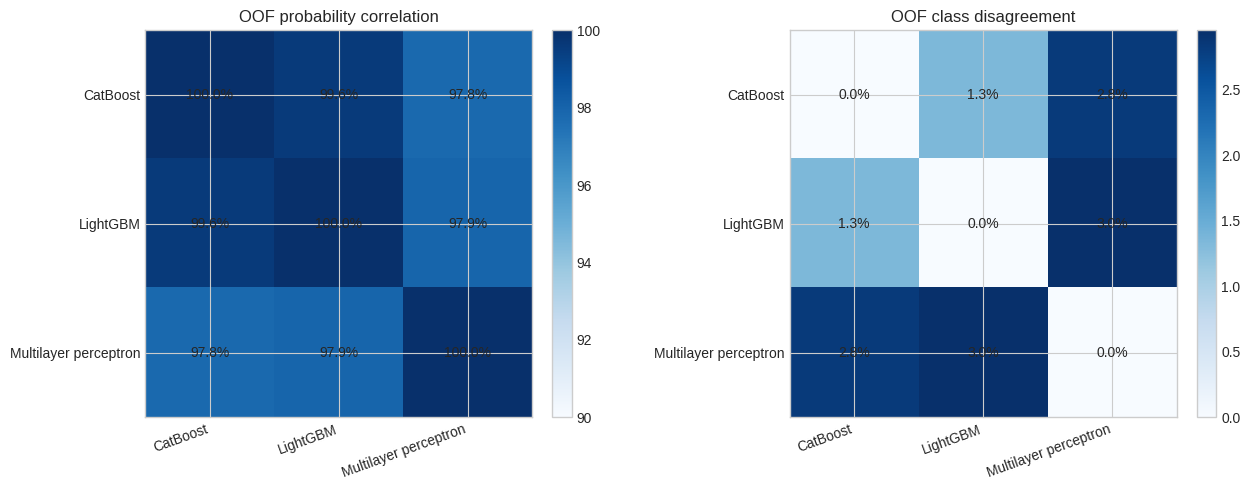

In [8]:
probability_correlation = pd.DataFrame(base_matrix, columns=base_names).corr()
disagreement = pd.DataFrame(index=base_names, columns=base_names, dtype=float)

for left_index, left_name in enumerate(base_names):
    for right_index, right_name in enumerate(base_names):
        disagreement.loc[left_name, right_name] = 100 * np.mean(
            base_class_matrix[:, left_index] != base_class_matrix[:, right_index]
        )

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for axis, matrix, title, suffix, vmin, vmax in [
    (axes[0], 100 * probability_correlation, "OOF probability correlation", "%", 90, 100),
    (axes[1], disagreement, "OOF class disagreement", "%", 0, disagreement.to_numpy().max()),
]:
    image = axis.imshow(matrix, cmap="Blues", vmin=vmin, vmax=max(vmax, vmin + 1))
    axis.set_xticks(range(len(base_names)), base_names, rotation=20, ha="right")
    axis.set_yticks(range(len(base_names)), base_names)
    axis.set_title(title)
    for row_index in range(len(base_names)):
        for column_index in range(len(base_names)):
            axis.text(
                column_index, row_index,
                f"{matrix.iloc[row_index, column_index]:.1f}{suffix}",
                ha="center", va="center",
            )
    fig.colorbar(image, ax=axis, fraction=.046, pad=.04)

plt.tight_layout()
plt.show()


## 6. Label-free ensemble recipes

These methods do not learn from the target labels:

- **Hard voting:** at least two of the three class votes must be `1`.
- **Equal soft voting:** arithmetic mean of the three probabilities.
- **Geometric averaging:** multiplies probabilities before taking a root; one very low probability has more influence.
- **Rank averaging:** converts each model’s probabilities to relative ranks before averaging. This reduces scale differences, but the result is a rank score rather than a calibrated probability.

All four keep threshold `0.50` for this controlled comparison.


In [9]:
hard_vote_scores = base_class_matrix.mean(axis=1)
soft_vote_scores = base_matrix.mean(axis=1)
geometric_scores = np.exp(
    np.log(np.clip(base_matrix, 1e-8, 1 - 1e-8)).mean(axis=1)
)
rank_matrix = np.column_stack([
    pd.Series(base_oof_scores[name]).rank(method="average", pct=True).to_numpy()
    for name in base_names
])
rank_average_scores = rank_matrix.mean(axis=1)

ensemble_scores = {
    "Hard voting": hard_vote_scores,
    "Equal soft voting": soft_vote_scores,
    "Geometric averaging": geometric_scores,
    "Rank averaging": rank_average_scores,
}

preview = pd.DataFrame({
    "method": list(ensemble_scores),
    "what is averaged": ["classes", "probabilities", "log probabilities", "relative ranks"],
    "learns from labels?": ["no", "no", "no", "no"],
})
display(preview.style.hide(axis="index"))


method,what is averaged,learns from labels?
Hard voting,classes,no
Equal soft voting,probabilities,no
Geometric averaging,log probabilities,no
Rank averaging,relative ranks,no


## 7. Learned ensembles without leakage

Weighted averaging and stacking use labels, so they need an extra protection layer.

For each **outer fold**:

1. keep that fold completely untouched for evaluation;
2. create four-fold **inner OOF** base probabilities using only the outer-training rows;
3. select blend weights or fit the stacking meta-model on those inner OOF probabilities;
4. apply the learned combiner to the untouched outer fold.

This is **nested cross-validation**. The outer fold never influences the learned weights or meta-model.


In [10]:
# Weight candidates use steps of 0.10 and always sum to 1.
weight_candidates = np.array([
    (first / 10, second / 10, (10 - first - second) / 10)
    for first in range(11)
    for second in range(11 - first)
])

nested_weighted_scores = np.zeros(len(y), dtype=float)
nested_stacked_scores = np.zeros(len(y), dtype=float)
weight_rows = []
stacking_rows = []

nested_start = perf_counter()
for outer_fold, (outer_train_index, outer_valid_index) in enumerate(folds, start=1):
    X_outer_train = X.iloc[outer_train_index]
    y_outer_train = y.iloc[outer_train_index]
    inner_folds = list(
        StratifiedKFold(
            n_splits=4, shuffle=True, random_state=RANDOM_STATE + outer_fold
        ).split(X_outer_train, y_outer_train)
    )

    inner_meta_features = np.zeros((len(outer_train_index), len(base_names)))
    for model_index, name in enumerate(base_names):
        inner_pipeline = Pipeline([
            ("preprocessor", make_preprocessor()),
            ("model", base_models[name]),
        ])
        inner_meta_features[:, model_index] = cross_val_predict(
            inner_pipeline,
            X_outer_train,
            y_outer_train,
            cv=inner_folds,
            method="predict_proba",
            n_jobs=1,
        )[:, 1]

    # These outer-fold base probabilities came from models trained without this outer fold.
    outer_meta_features = base_matrix[outer_valid_index]

    candidate_f1 = np.array([
        f1_score(y_outer_train, (inner_meta_features @ weights >= 0.50).astype(int))
        for weights in weight_candidates
    ])
    best_value = candidate_f1.max()
    tied_indices = np.flatnonzero(np.isclose(candidate_f1, best_value))
    equal_weight_distance = np.sum(
        (weight_candidates[tied_indices] - 1 / len(base_names)) ** 2,
        axis=1,
    )
    best_weight_index = tied_indices[np.argmin(equal_weight_distance)]
    best_weights = weight_candidates[best_weight_index]
    nested_weighted_scores[outer_valid_index] = outer_meta_features @ best_weights

    weight_rows.append({
        "outer fold": outer_fold,
        **{f"{name} weight": weight for name, weight in zip(base_names, best_weights)},
        "inner OOF F1": best_value,
    })

    meta_model = LogisticRegression(max_iter=5000, random_state=RANDOM_STATE + outer_fold)
    meta_model.fit(inner_meta_features, y_outer_train)
    nested_stacked_scores[outer_valid_index] = meta_model.predict_proba(
        outer_meta_features
    )[:, 1]
    stacking_rows.append({
        "outer fold": outer_fold,
        **{f"{name} coefficient": value for name, value in zip(base_names, meta_model.coef_[0])},
        "intercept": meta_model.intercept_[0],
    })
    print(f"Finished outer fold {outer_fold}/5")

nested_seconds = perf_counter() - nested_start
ensemble_scores["Nested weighted averaging"] = nested_weighted_scores
ensemble_scores["Nested logistic stacking"] = nested_stacked_scores

weight_selection = pd.DataFrame(weight_rows)
stacking_coefficients = pd.DataFrame(stacking_rows)
print(f"Nested learned ensembles completed in {nested_seconds:.1f}s")
display(weight_selection.style.hide(axis="index").format(precision=3))


Finished outer fold 1/5
Finished outer fold 2/5
Finished outer fold 3/5
Finished outer fold 4/5
Finished outer fold 5/5
Nested learned ensembles completed in 142.6s


outer fold,CatBoost weight,LightGBM weight,Multilayer perceptron weight,inner OOF F1
1,0.700,0.000,0.300,0.949
2,0.500,0.100,0.400,0.950
3,0.300,0.400,0.300,0.948
4,0.100,0.600,0.300,0.950
5,0.400,0.400,0.200,0.949


### How stable were the learned weights?

If the selected weights change sharply between outer folds, the “best” mixture is uncertain. Stability matters alongside the average score.

Stacking coefficients are not percentages: a positive coefficient means that a higher base probability pushes the meta-model toward “scored.”


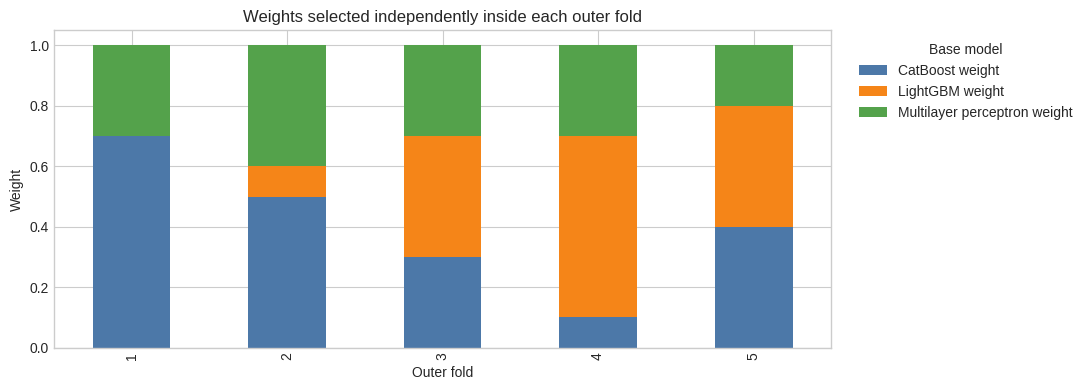

outer fold,CatBoost coefficient,LightGBM coefficient,Multilayer perceptron coefficient,intercept
1,7.209,0.659,1.524,-4.710
2,6.739,1.113,1.643,-4.760
3,6.810,0.938,1.683,-4.737
4,6.371,1.606,1.477,-4.716
5,6.721,0.854,1.820,-4.697


In [11]:
weight_columns = [f"{name} weight" for name in base_names]
weight_selection.set_index("outer fold")[weight_columns].plot(
    kind="bar", stacked=True, figsize=(11, 4),
    color=["#4C78A8", "#F58518", "#54A24B"],
)
plt.title("Weights selected independently inside each outer fold")
plt.xlabel("Outer fold")
plt.ylabel("Weight")
plt.legend(title="Base model", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

display(stacking_coefficients.style.hide(axis="index").format(precision=3))


## 8. Compare every method

All rows below use one prediction per training row that was produced without training the evaluated combiner on that row.

`fold standard deviation` measures ordinary variation across the five outer folds. A tiny F1 lead smaller than this variation is weak evidence.


In [12]:
ensemble_rows = []
for method, scores in ensemble_scores.items():
    extra_seconds = nested_seconds if method.startswith("Nested") else 0.0
    ensemble_rows.append(
        summarize_scores(method, scores, "Ensemble", extra_seconds)
    )

results = pd.concat([
    individual_results,
    pd.DataFrame(ensemble_rows),
], ignore_index=True).sort_values("f1", ascending=False).reset_index(drop=True)

display(results.style.hide(axis="index").format({
    "f1": "{:.4f}",
    "fold_std": "{:.4f}",
    "precision": "{:.4f}",
    "recall": "{:.4f}",
    "balanced_accuracy": "{:.4f}",
    "accuracy": "{:.4f}",
    "roc_auc": "{:.4f}",
    "extra_fit_seconds": "{:.1f}",
}))


category,method,f1,fold_std,precision,recall,balanced_accuracy,accuracy,roc_auc,extra_fit_seconds
Ensemble,Equal soft voting,0.9495,0.0052,0.9492,0.9498,0.9541,0.9545,0.9931,0.0
Ensemble,Geometric averaging,0.9485,0.0051,0.9512,0.9459,0.9531,0.9538,0.9930,0.0
Ensemble,Nested logistic stacking,0.9484,0.0046,0.9499,0.9470,0.9530,0.9536,0.9931,142.6
Ensemble,Nested weighted averaging,0.9484,0.0050,0.9485,0.9482,0.9531,0.9536,0.9930,142.6
Ensemble,Hard voting,0.9476,0.0052,0.9490,0.9462,0.9523,0.9529,0.9667,0.0
Individual model,Multilayer perceptron,0.9471,0.0023,0.9436,0.9507,0.9521,0.9523,0.9914,17.6
Individual model,CatBoost,0.9464,0.0054,0.9495,0.9433,0.9511,0.9519,0.9927,17.6
Individual model,LightGBM,0.9449,0.0065,0.9462,0.9437,0.9499,0.9505,0.9921,6.6
Ensemble,Rank averaging,0.9347,0.0066,0.8890,0.9852,0.9423,0.9380,0.9931,0.0


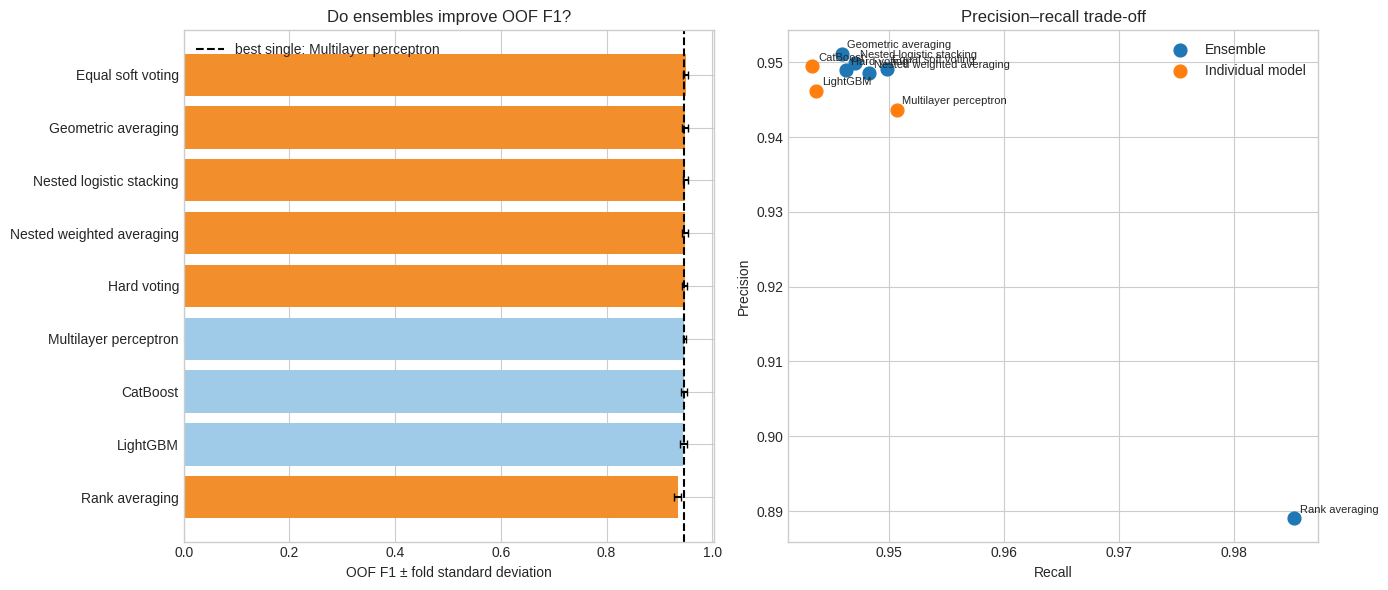

In [13]:
best_single = individual_results.sort_values("f1", ascending=False).iloc[0]
ordered = results.sort_values("f1")
colors = ordered["category"].map({"Individual model": "#A0CBE8", "Ensemble": "#F28E2B"})

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].barh(
    ordered["method"], ordered["f1"],
    xerr=ordered["fold_std"], capsize=3, color=colors,
)
axes[0].axvline(
    best_single["f1"], color="black", linestyle="--",
    label=f"best single: {best_single['method']}",
)
axes[0].set(title="Do ensembles improve OOF F1?", xlabel="OOF F1 ± fold standard deviation")
axes[0].legend()

for category, group in results.groupby("category"):
    axes[1].scatter(group["recall"], group["precision"], s=85, label=category)
for _, row in results.iterrows():
    axes[1].annotate(
        row["method"], (row["recall"], row["precision"]),
        xytext=(4, 4), textcoords="offset points", fontsize=8,
    )
axes[1].set(title="Precision–recall trade-off", xlabel="Recall", ylabel="Precision")
axes[1].legend()

plt.tight_layout()
plt.show()


### Concrete dataset example: when models disagree

The next rows have strong disagreement between the base probabilities.

The equal soft vote is a fixed recipe. Nested weighting and stacking were learned without using the displayed row’s outer-fold label.


In [14]:
base_disagreement = base_class_matrix.max(axis=1) != base_class_matrix.min(axis=1)
probability_spread = base_matrix.max(axis=1) - base_matrix.min(axis=1)
ensemble_class_matrix = np.column_stack([
    (soft_vote_scores >= 0.50).astype(int),
    (nested_weighted_scores >= 0.50).astype(int),
    (nested_stacked_scores >= 0.50).astype(int),
])
ensemble_disagreement = ensemble_class_matrix.max(axis=1) != ensemble_class_matrix.min(axis=1)
priority = 10 * base_disagreement + 5 * ensemble_disagreement + probability_spread
example_index = np.argsort(priority)[-8:][::-1]

example = pd.DataFrame({
    "actual": y.iloc[example_index].to_numpy(),
    **{f"{name} p": base_oof_scores[name][example_index] for name in base_names},
    "soft p": soft_vote_scores[example_index],
    "nested weighted p": nested_weighted_scores[example_index],
    "nested stacked p": nested_stacked_scores[example_index],
}, index=train.iloc[example_index]["id"].rename("penalty id"))

display(example.style.format(precision=3))
print("A probability of at least 0.50 becomes class 1 (scored).")


,actual,CatBoost p,LightGBM p,Multilayer perceptron p,soft p,nested weighted p,nested stacked p
penalty id,,,,,,,
10558,0,0.341,0.939,0.084,0.455,0.623,0.287
4010,0,0.479,0.854,0.027,0.453,0.568,0.437
4216,1,0.950,0.414,0.132,0.499,0.569,0.910
888,1,0.587,0.184,0.996,0.589,0.468,0.688
28,1,0.621,0.803,0.027,0.484,0.443,0.584
13787,0,0.637,0.838,0.082,0.519,0.435,0.646
13346,1,0.789,0.629,0.072,0.497,0.478,0.806
916,0,0.329,0.188,0.895,0.471,0.541,0.296


A probability of at least 0.50 becomes class 1 (scored).


## 9. Decision

An ensemble is kept only if it improves on the strongest individual model under the same outer-fold evidence.

If the gain is tiny compared with fold variation, we treat the models as practically tied and prefer the simpler option unless later calibration or threshold optimization changes the decision.


In [15]:
best_ensemble = results.loc[results["category"].eq("Ensemble")].iloc[0]
change = best_ensemble["f1"] - best_single["f1"]

print(f"Best individual model: {best_single['method']} | F1 {best_single['f1']:.4f}")
print(f"Best ensemble: {best_ensemble['method']} | F1 {best_ensemble['f1']:.4f}")
print(f"Ensemble change: {change:+.4f}")

if change > 0:
    chosen_method = best_ensemble["method"]
    print("Decision: carry the best ensemble into Notebook 13 alongside the best single model.")
else:
    chosen_method = best_single["method"]
    print("Decision: keep the best single model; the tested ensembles did not improve F1.")

results_dir = Path("/kaggle/working") if Path("/kaggle/working").exists() else PROJECT_ROOT / "results"
results_dir.mkdir(parents=True, exist_ok=True)
results.to_csv(results_dir / "12_ensemble_comparison.csv", index=False)
weight_selection.to_csv(results_dir / "12_nested_weight_selection.csv", index=False)

oof_export = pd.DataFrame({
    "id": train["id"],
    "actual": y,
    **{f"{name} probability": base_oof_scores[name] for name in base_names},
    **{f"{name} probability": scores for name, scores in ensemble_scores.items()},
})
oof_export.to_csv(results_dir / "12_oof_ensemble_probabilities.csv", index=False)

with (results_dir / "12_ensemble_decision.json").open("w", encoding="utf-8") as handle:
    json.dump({
        "dataset_fingerprint": dataset_fingerprint,
        "best_individual": best_single["method"],
        "best_ensemble": best_ensemble["method"],
        "ensemble_f1_change": float(change),
        "chosen_method": chosen_method,
    }, handle, indent=2)

print(f"Saved ensemble artifacts to: {results_dir}")


Best individual model: Multilayer perceptron | F1 0.9471
Best ensemble: Equal soft voting | F1 0.9495
Ensemble change: +0.0023
Decision: carry the best ensemble into Notebook 13 alongside the best single model.
Saved ensemble artifacts to: /kaggle/working


## Other useful ensemble methods

- **Bagging:** trains copies of one model on resampled rows and averages them. Random Forest is a bagging example.
- **Blending:** trains a combiner on one fixed holdout set. It is simpler than stacking but wastes training rows.
- **Weighted soft voting:** uses fixed expert-chosen weights rather than learning them.
- **OOF stacking:** trains a meta-model on OOF base predictions. Strict performance estimation still needs the nested outer layer used here.
- **Greedy ensemble selection:** repeatedly adds the model that improves the current ensemble most.
- **Out-of-fold stacking with nonlinear meta-models:** trees or neural networks can combine predictions, but they overfit more easily than logistic regression.

More models are not automatically better. Add a model only when its quality and different errors justify the extra complexity.


## Why this decision is justified

**Technical evidence:** every method uses the same OOF base predictions, folds, threshold, and metrics. Learned weights and stacking are evaluated through a nested outer fold, so the evaluated row’s label never trains its combiner.

**Theoretical reason:** averaging can reduce model-specific variance, but highly correlated base models share many mistakes. The final choice balances F1 gain, fold variability, diversity, and implementation complexity.
